# Walmart Weekly Sales Forecasting

**Goal:** predict the weekly sales of every department of 45 Walmart stores, for the 39 weeks that follow the data we have (Nov 2012 → Jul 2013). Data from the Kaggle competition [Walmart Recruiting: Store Sales Forecasting](https://www.kaggle.com/competitions/walmart-recruiting-store-sales-forecasting).

**Metric:** the competition is scored with the **WMAE** (Weighted Mean Absolute Error), where holiday weeks count 5 times more than normal weeks.

**Roadmap of this notebook:**

1. Load the data and understand each file
2. Merge the tables into one dataset
3. Prepare the dates and clean missing values
4. Explore the data (EDA) to find what drives sales
5. Engineer holiday features from what the EDA showed
6. Prepare a time-based train / validation split
7. Train models from the simplest to the most complex
8. Re-rank them with the official Kaggle metric
9. Understand the best baseline model (predictions vs reality, SHAP)
10. Final model: LightGBM + seasonal naive ensemble, built from the lessons of steps 8 and 9 and of `Notebook_Experiments.ipynb`

**Final result:** WMAE **1,818** on a full validation year that includes Thanksgiving and Christmas.

## 1. Loading the data

**Why this step?** Before building anything, we need to know what each file contains, which columns can be used as inputs, and what exactly we have to predict.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

train = pd.read_csv("./Data/train.csv")
test = pd.read_csv("./Data/test.csv")
features = pd.read_csv("./Data/features.csv")
stores = pd.read_csv("./Data/stores.csv")
sampleSubmission = pd.read_csv("./Data/sampleSubmission.csv")

In [2]:
train.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [3]:
test.head()

,Store,Dept,Date,IsHoliday
0,1,1,2012-11-02,False
1,1,1,2012-11-09,False
2,1,1,2012-11-16,False
3,1,1,2012-11-23,True
4,1,1,2012-11-30,False


`train.csv` contains the weekly sales (`Weekly_Sales`) of each store and department. `test.csv` has the same keys but **no sales column**: these are the weeks we have to predict, and Kaggle keeps the real values hidden to score the submissions.

In [4]:
features.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [5]:
stores.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [6]:
features.info()

<class 'pandas.DataFrame'>
RangeIndex: 8190 entries, 0 to 8189
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         8190 non-null   int64  
 1   Date          8190 non-null   str    
 2   Temperature   8190 non-null   float64
 3   Fuel_Price    8190 non-null   float64
 4   MarkDown1     4032 non-null   float64
 5   MarkDown2     2921 non-null   float64
 6   MarkDown3     3613 non-null   float64
 7   MarkDown4     3464 non-null   float64
 8   MarkDown5     4050 non-null   float64
 9   CPI           7605 non-null   float64
 10  Unemployment  7605 non-null   float64
 11  IsHoliday     8190 non-null   bool   
dtypes: bool(1), float64(9), int64(1), str(1)
memory usage: 791.9 KB


`features.csv` adds context for each store and week (temperature, fuel price, promotions called MarkDowns, CPI, unemployment), and `stores.csv` gives the type (A, B, C) and size of each store.

The `info()` output shows many missing values in the **MarkDown** columns: promotions were only recorded from November 2011. CPI and Unemployment are also missing for the last months of 2013.

## 2. Merging the tables

**Why this step?** The sales are in one file and their context (store type, promotions, economy) in two others. A model needs all the information of a week on a single row, so we join the tables on their common keys.

First, store information is added to the weekly features (common key: `Store`). Then this table is joined to the sales on `Store`, `Date` and `IsHoliday`.

In [7]:
feature_store_merged = features.merge(stores, how="inner", on="Store")

train_final_merged = train.merge(feature_store_merged, on=["Store", "Date", "IsHoliday"])
train_final_merged = train_final_merged.sort_values(by=["Store", "Dept", "Date"]).reset_index(drop=True)

print(train_final_merged.shape)
train_final_merged.head()

(421570, 16)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


## 3. Preparing the dates and cleaning missing values

**Why this step?** A model cannot use a date written as text. What matters for sales is *when in the year* a week is, because shopping follows the calendar (holidays, back to school, end of year). We therefore convert `Date` to a real date and extract:

* `Year`, to capture a possible trend from one year to the next,
* `Week_Of_Year` (1 to 52), to capture seasonality.

Month or day of the month would be redundant with the week of the year, so they are not created.

The missing **MarkDowns** are replaced by 0: a missing promotion value means there was no promotion that week.

In [8]:
train_final_merged["Date"] = pd.to_datetime(train_final_merged["Date"])
train_final_merged["Year"] = train_final_merged["Date"].dt.year
train_final_merged["Week_Of_Year"] = train_final_merged["Date"].dt.isocalendar().week.astype(int)

markdown_cols = ["MarkDown1", "MarkDown2", "MarkDown3", "MarkDown4", "MarkDown5"]
train_final_merged[markdown_cols] = train_final_merged[markdown_cols].fillna(0)

train_final_merged.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size,Year,Week_Of_Year
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,A,151315,2010,5
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,A,151315,2010,6
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,A,151315,2010,7
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,A,151315,2010,8
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,A,151315,2010,9


In [9]:
train_final_merged.describe()

,Store,Dept,Date,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size,Year,Week_Of_Year
count,421570.000000,421570.000000,421570,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,2011-06-18 08:30:31.963375,15981.258123,60.090059,3.361027,2590.074819,879.974298,468.087665,1083.132268,1662.772385,171.201947,7.960289,136727.915739,2010.968591,25.826762
min,1.000000,1.000000,2010-02-05 00:00:00,-4988.940000,-2.060000,2.472000,0.000000,-265.760000,-29.100000,0.000000,0.000000,126.064000,3.879000,34875.000000,2010.000000,1.000000
25%,11.000000,18.000000,2010-10-08 00:00:00,2079.650000,46.680000,2.933000,0.000000,0.000000,0.000000,0.000000,0.000000,132.022667,6.891000,93638.000000,2010.000000,14.000000
50%,22.000000,37.000000,2011-06-17 00:00:00,7612.030000,62.090000,3.452000,0.000000,0.000000,0.000000,0.000000,0.000000,182.318780,7.866000,140167.000000,2011.000000,26.000000
75%,33.000000,74.000000,2012-02-24 00:00:00,20205.852500,74.280000,3.738000,2809.050000,2.200000,4.540000,425.290000,2168.040000,212.416993,8.572000,202505.000000,2012.000000,38.000000
max,45.000000,99.000000,2012-10-26 00:00:00,693099.360000,100.140000,4.468000,88646.760000,104519.540000,141630.610000,67474.850000,108519.280000,227.232807,14.313000,219622.000000,2012.000000,52.000000
std,12.785297,30.492054,NaN,22711.183519,18.447931,0.458515,6052.385934,5084.538801,5528.873453,3894.529945,4207.629321,39.159276,1.863296,60980.583328,0.796876,14.151887


## 4. Exploratory Data Analysis

**Why this step?** Before choosing a model, we need to understand what makes sales go up or down. Each finding of this section tells us which information the model needs, and later guides the feature engineering.

### 4.1 Seasonality: total sales by week of the year

In [10]:
total_weekly_sales = train_final_merged.groupby("Week_Of_Year", as_index=False)["Weekly_Sales"].sum()

In [11]:
fig = px.line(
    total_weekly_sales,
    x="Week_Of_Year",
    y="Weekly_Sales",
    title="Total Walmart Stores Sales by Weeks of the Year",
    labels={
        "Week_Of_Year": "Week of the Year",
        "Weekly_Sales": "Total Weekly Sales ($)"
    },
)

fig.update_traces(
    hovertemplate="Week %{x}<br>Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x",
    width=800,
    height=500,
    title_x = 0.5
)

fig.show()

Sales peak around weeks 7, 14, 22, 27, 40, 47 and 51, and drop at weeks 44, 48 and 52. The biggest peaks are **Thanksgiving (week 47)** and the **weeks before Christmas (week 51)**: the calendar is a major driver of sales.

### 4.2 Trend: do sales grow from year to year?

**Why?** If sales grow every year, the model must learn a trend on top of the seasonality.

In [12]:
yearly_sales = train_final_merged.groupby("Year")["Weekly_Sales"].sum().reset_index()
yearly_sales

,Year,Weekly_Sales
0,2010,2.288886e+09
1,2011,2.448200e+09
2,2012,2.000133e+09


In [13]:
fig = px.line(yearly_sales, 
              x="Year", 
              y="Weekly_Sales", 
              title="Walmart Total Sales Trend by Year (2010-2012)",
              labels={
                    "Year": "Year",
                    "Weekly_Sales": "Total Sales ($)"
                    },)

fig.update_traces(
    hovertemplate="Year: %{x}<br>Total Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x",
    width=1000,
    height=500,
    title_x=0.5
)

At first sight, sales increase from 2010 to 2011 (≈ +160M$) and then drop heavily in 2012 (≈ -450M$).

**But this is a data coverage effect, not a real drop:** the data runs from 2010-02-05 to 2012-10-26, so each year has a different number of weeks (2010: 48, 2011: 52, 2012: 43), and 2012 is missing its November to December peak.

Comparing only the **39 weeks present in all three years** (ISO weeks 5 to 43), total sales are actually **stable**: 1,797M$ in 2010, 1,786M$ in 2011 and 1,831M$ in 2012 (+2.5%). Comparing the same weeks year-over-year (the "Sales by Year" plot below) is the fair comparison.

In [14]:
sales_year_week = train_final_merged.groupby(["Year", "Week_Of_Year"], as_index=False)["Weekly_Sales"].sum()

In [15]:
fig = px.line(
    sales_year_week,
    x="Week_Of_Year",
    y="Weekly_Sales",
    color="Year",
    title="Walmart Weekly Sales by Year",
    labels={
        "Week_Of_Year": "Week of Year",
        "Weekly_Sales": "Total Weekly Sales ($)"
    }
)

fig.update_traces(
    hovertemplate="Year %{Year}<br>Week %{x}<br>Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified",
    width=1100,
    height=550,
    title_x=0.5
)

fig.show()

Week by week, the three years almost overlap: the seasonal pattern repeats every year with the same shape. This is an important clue for later: **"the same week last year" is already a very good predictor**.

### 4.3 Store types

**Why?** `stores.csv` gives each store a type (A, B, C). If the types behave differently, the model needs this information.

In [16]:
type_sales = train_final_merged.groupby(["Week_Of_Year", "Type"])["Weekly_Sales"].sum().reset_index()

In [17]:
fig = px.line(type_sales, 
              x="Week_Of_Year", 
              y="Weekly_Sales", 
              title="Sales by Week Over the Year for each Store Type",
              color= "Type",
              labels={
                    "Week_Of_Year": "Week of the Year",
                    "Weekly_Sales": "Total Sales ($)"
                    },)

fig.update_traces(
    hovertemplate="Week: %{x}<br>Total Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x",
    width=1000,
    height=500,
    title_x=0.5
)

Type A stores sell the most, followed by B and C. Type C stores have stable sales all year round, while types A and B follow the same seasonal pattern with strong peaks at Thanksgiving and before Christmas. The store type is therefore useful, both for the sales level and for the size of the holiday peaks.

### 4.4 Holiday weeks

**Why?** The Kaggle metric gives 5 times more weight to holiday weeks: we need to know how different they are.

In [18]:
week_counts = train_final_merged[["Date", "IsHoliday"]].drop_duplicates().groupby("IsHoliday").size()
holiday_effect = train_final_merged.groupby("IsHoliday", as_index=False)["Weekly_Sales"].mean()
print(week_counts)
holiday_effect

IsHoliday
False    133
True      10
dtype: int64


,IsHoliday,Weekly_Sales
0,False,15901.445069
1,True,17035.823187


In [19]:
fig = px.bar(
    holiday_effect,
    x="IsHoliday",
    y="Weekly_Sales",
    title="Impact of Holidays on Weekly Sales",
    labels={
        "IsHoliday": "Week Type",
        "Weekly_Sales": "Average Weekly Sales ($)"
    },
    text_auto=".2s"
)

fig.update_traces(
    hovertemplate="%{x}<br>Avg Sales: $%{y:,.0f}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    width=600,
    height=450,
    title_x=0.5
)

fig.show()

Only 10 weeks out of 143 are holiday weeks, but their average sales are **7.1% higher** (17,036 vs 15,901). Combined with their weight of 5 in the metric, getting these weeks right matters a lot.

### 4.5 Promotions (MarkDowns)

**Why?** Promotions are the only variable that Walmart controls. If they drive sales, the model should use them.

In [20]:
markdown_cols = ["MarkDown1","MarkDown2","MarkDown3","MarkDown4","MarkDown5"]

weekly_markdown_sales = (
    train_final_merged
    .groupby("Week_Of_Year", as_index=False)
    .agg({
        "Weekly_Sales": "sum",
        **{c: "sum" for c in markdown_cols}
    })
)

In [21]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=weekly_markdown_sales["Week_Of_Year"],
    y=weekly_markdown_sales["Weekly_Sales"],
    name="Total Sales",
    yaxis="y1",
    line=dict(width=4)
))

for md in markdown_cols:
    fig.add_trace(go.Scatter(
        x=weekly_markdown_sales["Week_Of_Year"],
        y=weekly_markdown_sales[md],
        name=md,
        yaxis="y2",
        line=dict(width=2, dash="dot")
    ))

fig.update_layout(
    title="Weekly Sales vs MarkDown Campaigns",
    title_x=0.5,
    xaxis_title="Week of the Year",

    yaxis=dict(
        title="Total Sales ($)",
        showgrid=True
    ),

    yaxis2=dict(
        title="MarkDown Amount ($)",
        overlaying="y",
        side="right",
        showgrid=False
    ),

    template="plotly_white",
    hovermode="x",
    width=1100,
    height=550
)

fig.show()

When MarkDowns spike, sales also spike at the same time or just after. But the biggest promotions happen during the holiday season anyway, so part of this link may simply be the calendar.

### 4.6 Correlations

**Why?** The plots above looked at variables one by one. A correlation matrix compares all numerical variables at once, to see which ones move together with the sales.

In [22]:
numeric_cols = train_final_merged.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
corr_matrix["Weekly_Sales"].sort_values(ascending=False)

Weekly_Sales    1.000000
Size            0.243828
Dept            0.148032
MarkDown5       0.050465
MarkDown1       0.047172
MarkDown3       0.038562
MarkDown4       0.037467
Week_Of_Year    0.027673
MarkDown2       0.020716
Fuel_Price     -0.000120
Temperature    -0.002312
Year           -0.010111
CPI            -0.020921
Unemployment   -0.025864
Store          -0.085195
Name: Weekly_Sales, dtype: float64

In [23]:
fig = px.imshow(
    corr_matrix,
    text_auto="0.2f",
    aspect="auto",
    color_continuous_scale="RdBu",
    title="Correlation Matrix of Walmart Features"
)

fig.update_layout(
    width=1000,
    height=900,
    title_x=0.5
)

fig.show()

Store characteristics dominate: **store size** has the strongest correlation with sales (0.24), followed by the **department** (0.15), because product categories (groceries, electronics, clothing) live on very different sales scales. The MarkDowns have small positive correlations (0.02 to 0.05). Temperature, fuel price, CPI and unemployment show almost no correlation: weekly demand is not strongly affected by short-term economic or weather changes.

These are **linear** correlations only: they cannot see effects such as "sales jump a few weeks before Christmas". This is why the next step builds holiday features, and why non-linear models will be needed.

## 5. Feature engineering: distance to the holidays

**Why this step?** The EDA showed that the biggest sales happen **around** the holidays, not only during the holiday week itself: shopping builds up before Thanksgiving and Christmas. `IsHoliday` only flags the holiday week, so it cannot describe this build-up.

For each week we compute the number of days until Thanksgiving, Christmas, the Super Bowl and Labor Day of the same year. The dates are the Fridays of each holiday week, since Walmart weeks end on a Friday.

In [24]:
THANKSGIVING_WEEK = {
    2010: pd.Timestamp("2010-11-26"),
    2011: pd.Timestamp("2011-11-25"),
    2012: pd.Timestamp("2012-11-23"),
    2013: pd.Timestamp("2013-11-29"),  
}

CHRISTMAS_WEEK = {
    2010: pd.Timestamp("2010-12-31"),
    2011: pd.Timestamp("2011-12-30"),
    2012: pd.Timestamp("2012-12-28"),
    2013: pd.Timestamp("2013-12-27"),  
}

SUPER_BOWL_WEEK = {
    2010: pd.Timestamp("2010-02-12"),
    2011: pd.Timestamp("2011-02-11"),
    2012: pd.Timestamp("2012-02-10"),
    2013: pd.Timestamp("2013-02-08"),  
}

LABOR_DAY_WEEK = {
    2010: pd.Timestamp("2010-09-10"),
    2011: pd.Timestamp("2011-09-09"),
    2012: pd.Timestamp("2012-09-07"),
    2013: pd.Timestamp("2013-09-06"),  
}

In [25]:
def add_days_to_holidays(df):
    df = df.copy()
    df["Days_to_Thanksgiving"] = df["Date"].apply(lambda d: (THANKSGIVING_WEEK[d.year] - d).days).astype(int)
    df["Days_to_Christmas"]    = df["Date"].apply(lambda d: (CHRISTMAS_WEEK[d.year] - d).days).astype(int)
    df["Days_to_SuperBowl"]     = df["Date"].apply(lambda d: (SUPER_BOWL_WEEK[d.year] - d).days).astype(int)
    df["Days_to_LaborDay"]      = df["Date"].apply(lambda d: (LABOR_DAY_WEEK[d.year] - d).days).astype(int)
    return df

In [26]:
train_final_merged = add_days_to_holidays(train_final_merged)
train_final_merged[["Date", "Days_to_SuperBowl", "Days_to_LaborDay", "Days_to_Thanksgiving", "Days_to_Christmas"]].head()

,Date,Days_to_SuperBowl,Days_to_LaborDay,Days_to_Thanksgiving,Days_to_Christmas
0,2010-02-05,7,217,294,329
1,2010-02-12,0,210,287,322
2,2010-02-19,-7,203,280,315
3,2010-02-26,-14,196,273,308
4,2010-03-05,-21,189,266,301


In [27]:
train_final_merged[["Weekly_Sales", "Week_Of_Year", "Days_to_Thanksgiving", "Days_to_Christmas",
                    "Days_to_SuperBowl", "Days_to_LaborDay"]].corr()["Weekly_Sales"]

Weekly_Sales            1.000000
Week_Of_Year            0.027673
Days_to_Thanksgiving   -0.027673
Days_to_Christmas      -0.027673
Days_to_SuperBowl      -0.027673
Days_to_LaborDay       -0.027673
Name: Weekly_Sales, dtype: float64

The four new features have exactly the same linear correlation with sales as `Week_Of_Year` (with the opposite sign). Within a year, the distance to a holiday is just the week number shifted, so for a linear model they add nothing. A **tree-based model**, however, can use them to cut the year at the right place ("less than 30 days before Christmas"), which is why they are kept.

## 6. Preparing the data for modeling

**Why this step?** To know how well a model will predict the future, we must test it on weeks it has **never seen**. With time series, a random split would let the model learn from weeks that come *after* the ones it is tested on, which inflates the scores. We therefore use a **time-based split**: train on 2010 and 2011, validate on 2012.

`Date` is removed (its information is now in `Year`, `Week_Of_Year` and the holiday distances) and `IsHoliday` is converted to 0/1.

In [28]:
train_final_merged["IsHoliday"] = train_final_merged["IsHoliday"].astype(int)
model_data = train_final_merged.drop(columns=["Date"])

train_data = model_data[model_data["Year"] <= 2011]
val_data = model_data[model_data["Year"] == 2012]

X_train = train_data.drop(columns=["Weekly_Sales"])
y_train = train_data["Weekly_Sales"]
X_val = val_data.drop(columns=["Weekly_Sales"])
y_val = val_data["Weekly_Sales"]

print("Train rows:", X_train.shape, "| Validation rows:", X_val.shape)

Train rows: (294132, 20) | Validation rows: (127438, 20)


**Preprocessing:**

* `Type` is the only text column. It is encoded as an ordered number, **C = 0 < B = 1 < A = 2**, following the sales volume seen in the EDA.
* Numerical columns are standardized (mean 0, standard deviation 1). This matters for the linear models, which are sensitive to the scale of each variable; tree models are not affected.

Both steps are wrapped in a `ColumnTransformer` so that every model receives exactly the same preprocessing.

In [29]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

num_data = X_train.select_dtypes(include=[np.number]).columns
cat_data = X_train.select_dtypes(exclude=[np.number]).columns

preprocessing = ColumnTransformer([
    ("Categorical data", Pipeline([("Ordinal Encoding", OrdinalEncoder(categories=[["C", "B", "A"]]))]), cat_data),
    ("Numerical data", Pipeline([("Numerical processing", StandardScaler())]), num_data),
], remainder="drop")

## 7. Modeling: from the simplest model to the most complex

**Why this order?** We start with the simplest model as a baseline. Each result then tells us what is missing, and the next model is chosen to fix that specific problem. This way, every extra bit of complexity has to prove that it is useful.

For each model we report, on the 2012 validation set:

* **MAE**: average error in dollars per prediction,
* **RMSE**: like the MAE but large errors are penalized more,
* **R²**: share of the variance of sales explained by the model (1 = perfect),
* **Train R² and gap**: if the model is much better on the training data than on validation, it is memorizing instead of learning (overfitting).

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = {}  # validation predictions of each model, reused in section 8


def evaluate_model(name, model):
    pipeline = Pipeline([("Preprocessing", clone(preprocessing)), ("Model", model)])
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)
    r2_val = r2_score(y_val, y_pred)
    r2_train = r2_score(y_train, pipeline.predict(X_train))
    results[name] = y_pred

    print(f"{name}")
    print(f"  MAE:      {mean_absolute_error(y_val, y_pred):,.2f}")
    print(f"  RMSE:     {np.sqrt(mean_squared_error(y_val, y_pred)):,.2f}")
    print(f"  Val R²:   {r2_val:.4f}")
    print(f"  Train R²: {r2_train:.4f}   (gap: {r2_train - r2_val:.4f})")
    return pipeline

### 7.1 Linear Regression

**Why start here?** It is the simplest possible model: a weighted sum of the features. If it worked well, there would be no reason to use anything more complex.

In [31]:
from sklearn.linear_model import LinearRegression

LR_pipeline = evaluate_model("Linear Regression", LinearRegression())

Linear Regression
  MAE:      14,299.03
  RMSE:     21,118.36
  Val R²:   0.0886
  Train R²: 0.0854   (gap: -0.0031)


**Result:** a complete failure. With an R² of 0.09, the model explains only 9% of the variance in weekly sales, barely better than always predicting the average, and it is off by more than $14,000 per prediction.

This was expected: sales depend on holiday spikes and on combinations of store and department that a straight line cannot represent. Before giving up on linear models, we check that the problem is not the way the weights were computed.

### 7.2 Stochastic Gradient Descent

**Why?** `SGDRegressor` is also a linear model, but it finds its weights by gradient descent instead of solving an equation. If it performed much better, the problem would come from the solver, not from the model.

In [32]:
from sklearn.linear_model import SGDRegressor

SGD_pipeline = evaluate_model("SGD Regressor", SGDRegressor(max_iter=1000, random_state=42))

SGD Regressor
  MAE:      14,145.01
  RMSE:     21,326.32
  Val R²:   0.0705
  Train R²: 0.0828   (gap: 0.0123)


**Result:** almost identical (R² 0.07). Same model, same limit: the relationship between the features and the sales is **not linear**. We need a model that can learn thresholds and interactions, such as a decision tree.

### 7.3 Decision Tree

**Why?** A decision tree splits the data with simple rules ("if Dept is 92 and Size is above 150,000, then..."). It can represent non-linear effects and interactions that a linear model cannot.

In [33]:
from sklearn.tree import DecisionTreeRegressor

DT_pipeline = evaluate_model("Decision Tree (default)", DecisionTreeRegressor(random_state=42))

Decision Tree (default)
  MAE:      2,967.58
  RMSE:     6,717.18
  Val R²:   0.9078
  Train R²: 1.0000   (gap: 0.0922)


**Result:** a huge jump, from an R² of 0.09 to 0.91, which confirms that the data is highly non-linear. But the **train R² is 1.0**: the tree grew until it memorized every training row. A gap of 0.09 between train and validation means it would not be reliable on new data. The next step is to limit its growth.

In [34]:
DT_pipeline = evaluate_model("Decision Tree (tuned)",
                             DecisionTreeRegressor(random_state=42, max_depth=10, min_samples_leaf=10,
                                                   min_samples_split=20))

Decision Tree (tuned)
  MAE:      4,623.85
  RMSE:     8,132.41
  Val R²:   0.8648
  Train R²: 0.8656   (gap: 0.0007)


**Result:** by limiting the depth and the size of the leaves, the train / validation gap almost disappears (0.0007): the tree now learns general patterns. But the validation R² drops to 0.86. A single tree has to choose between memorizing and missing details. To get both accuracy and generalization, we combine many trees.

### 7.4 Random Forest

**Why?** A Random Forest trains many trees on random subsets of the data and averages them. Each tree overfits in its own way, and the average cancels a large part of these individual errors.

In [35]:
from sklearn.ensemble import RandomForestRegressor

RF_pipeline = evaluate_model("Random Forest (default)",
                             RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))

Random Forest (default)
  MAE:      2,272.61
  RMSE:     5,003.30
  Val R²:   0.9488
  Train R²: 0.9962   (gap: 0.0474)


**Result:** the best model so far, with a validation R² of 0.949 and an MAE of about $2,270. The train R² of 0.996 still shows a gap of 0.047: with no limits, each tree is still memorizing. As with the single tree, we limit their growth.

In [36]:
RF_pipeline = evaluate_model("Random Forest (tuned)",
                             RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=10,
                                                   random_state=42, n_jobs=-1))

Random Forest (tuned)
  MAE:      2,332.82
  RMSE:     5,148.66
  Val R²:   0.9458
  Train R²: 0.9728   (gap: 0.0270)


**Result:** the validation R² barely moves (0.949 → 0.946) while the overfitting gap is almost cut in half (0.047 → 0.027). This is a more trustworthy model for unseen data.

Random Forest builds its trees **independently** and averages them. Another family of methods, **boosting**, builds trees **one after the other**, each new tree focusing on the errors of the previous ones. That is what we try next.

### 7.5 AdaBoost

**Why?** AdaBoost is the original boosting algorithm: after each tree, it increases the weight of the rows that were badly predicted.

In [37]:
from sklearn.ensemble import AdaBoostRegressor

Ada_pipeline = evaluate_model("AdaBoost", AdaBoostRegressor(n_estimators=100, random_state=42))

AdaBoost
  MAE:      22,726.75
  RMSE:     26,874.78
  Val R²:   -0.4761
  Train R²: -0.6408   (gap: -0.1648)


**Result:** a negative R² on both train and validation, which means it is worse than always predicting the average. Its own mechanism works against it: by giving more and more weight to the hardest rows, it became obsessed with the extreme holiday spikes and lost the normal weeks. Boosting needs a more robust approach: **gradient boosting**, which corrects the errors step by step without re-weighting the rows.

### 7.6 XGBoost

**Why?** XGBoost is a gradient boosting implementation with built-in regularization, designed to avoid exactly the kind of overfitting seen above. It runs on the GPU.

In [38]:
from xgboost import XGBRegressor

XGB_pipeline = evaluate_model("XGBoost (default)",
                              XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1,
                                           device="cuda", tree_method="hist"))

C:\Users\hamoud\miniconda3\envs\torch-nightly\Lib\site-packages\xgboost\core.py:751: UserWarning: [15:36:43] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


XGBoost (default)
  MAE:      3,317.95
  RMSE:     5,490.89
  Val R²:   0.9384
  Train R²: 0.9470   (gap: 0.0086)


**Result:** with default settings, XGBoost already reaches an R² of 0.938 with a very small gap (0.009). It learns slowly but safely, so we give it more trees, deeper trees, and random sampling of rows and columns.

In [39]:
XGB_pipeline = evaluate_model("XGBoost (tuned)",
                              XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=8, subsample=0.8,
                                           colsample_bytree=0.8, min_child_weight=5, random_state=42,
                                           n_jobs=-1, device="cuda", tree_method="hist"))

XGBoost (tuned)
  MAE:      2,732.26
  RMSE:     4,829.29
  Val R²:   0.9523
  Train R²: 0.9759   (gap: 0.0236)


**Result:** tuned XGBoost has the **best R² (0.9523) and RMSE (4,829)** of all models, with an MAE of $2,732 and a small train / validation gap (0.024).

To check whether this comes from XGBoost itself or from gradient boosting in general, we try a second gradient boosting library.

### 7.7 LightGBM

**Why?** LightGBM is another gradient boosting library. It grows its trees leaf by leaf instead of level by level, which often makes it faster and sometimes more accurate.

In [40]:
from lightgbm import LGBMRegressor

LGBM_pipeline = evaluate_model("LightGBM",
                               LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=8, num_leaves=63,
                                             subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
                                             random_state=42, n_jobs=-1, device="gpu", verbose=-1))

C:\Users\hamoud\miniconda3\envs\torch-nightly\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


C:\Users\hamoud\miniconda3\envs\torch-nightly\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


LightGBM
  MAE:      3,122.19
  RMSE:     5,324.27
  Val R²:   0.9421
  Train R²: 0.9553   (gap: 0.0132)


**Result:** an R² of 0.942 and an MAE of about $3,120, close to XGBoost but behind the tuned version. Its settings were not tuned here, so this does not mean LightGBM is weaker; it confirms that **gradient boosting** in general works well on this data.

All the models so far were ranked with R², but R² is not the metric of the competition. Before choosing a model, we need to check whether the ranking holds with the official metric.

## 8. Evaluation with the official Kaggle metric: WMAE

**Why this step?** So far the models were compared with R², but the competition is not scored with R². It uses the **Weighted Mean Absolute Error**:

$$WMAE = \frac{\sum_i w_i \, |y_i - \hat{y}_i|}{\sum_i w_i}, \qquad w_i = \begin{cases} 5 & \text{if holiday week} \\ 1 & \text{otherwise} \end{cases}$$

Holiday weeks count **5 times more**, so a model that misses the holiday peaks is heavily penalized. The ranking of the models may change with this metric.

In [41]:
def wmae(y_true, y_pred, is_holiday):
    weights = np.where(is_holiday, 5, 1)
    return np.sum(weights * np.abs(np.asarray(y_true) - np.asarray(y_pred))) / np.sum(weights)


ranking = pd.DataFrame([
    {"Model": name,
     "WMAE": wmae(y_val, preds, X_val["IsHoliday"]),
     "MAE": mean_absolute_error(y_val, preds),
     "R²": r2_score(y_val, preds)}
    for name, preds in results.items()
]).sort_values("WMAE").reset_index(drop=True)

print(ranking.to_string(formatters={"WMAE": "{:,.0f}".format, "MAE": "{:,.0f}".format, "R²": "{:.4f}".format}))

                     Model   WMAE    MAE      R²
0  Random Forest (default)  2,286  2,273  0.9488
1    Random Forest (tuned)  2,367  2,333  0.9458
2          XGBoost (tuned)  2,752  2,732  0.9523
3  Decision Tree (default)  2,988  2,968  0.9078
4                 LightGBM  3,149  3,122  0.9421
5        XGBoost (default)  3,361  3,318  0.9384
6    Decision Tree (tuned)  4,664  4,624  0.8648
7            SGD Regressor 14,155 14,145  0.0705
8        Linear Regression 14,374 14,299  0.0886
9                 AdaBoost 22,599 22,727 -0.4761


In [42]:
y_pred_xgb = results["XGBoost (tuned)"]
holiday_mask = (X_val["IsHoliday"] == 1).values
print(f"XGBoost MAE on holiday weeks:     {mean_absolute_error(y_val[holiday_mask], y_pred_xgb[holiday_mask]):,.0f}")
print(f"XGBoost MAE on non-holiday weeks: {mean_absolute_error(y_val[~holiday_mask], y_pred_xgb[~holiday_mask]):,.0f}")

XGBoost MAE on holiday weeks:     2,857
XGBoost MAE on non-holiday weeks: 2,726


**Result:** with the official metric, the ranking changes.

* **The Random Forests have the lowest WMAE** (2,286 for the default one, 2,367 for the tuned one), while **XGBoost keeps the best R²** (0.9523) and RMSE. R² and RMSE square the errors, so they reward XGBoost for handling the few very large sales values better. WMAE and MAE reward the Random Forests for being closer on a typical week.
* The default Random Forest wins on WMAE but overfits more (train / validation gap 0.047 vs 0.027), and a tuned Random Forest file weighs 182 MB versus 3.9 MB for XGBoost, which is too heavy to deploy comfortably.
* XGBoost's error on holiday weeks (2,857) is almost the same as on normal weeks (2,726). This is suspicious, since the EDA showed that holiday weeks are the hardest. The explanation: the 2012 validation data stops in October, so its only holiday weeks are the Super Bowl and Labor Day. **Thanksgiving and Christmas were never tested.**

None of these baseline models is the final one. The next section looks more closely at what XGBoost does, to understand how to improve it.

## 9. Understanding the baseline model

**Why this step?** A score summarizes the error in one number, but it does not say **where** the model is wrong or **what** it relies on. Before trying to improve it, we look at its predictions against reality and at the features it uses. We study the tuned XGBoost, the model with the best R².

### 9.1 Predictions vs actual sales (2012 validation)

In [43]:
val_plot = val_data[["Store", "Dept", "Year", "Week_Of_Year"]].copy()
val_plot["Actual"] = y_val.values
val_plot["Predicted"] = y_pred_xgb

weekly_val = val_plot.groupby("Week_Of_Year", as_index=False)[["Actual", "Predicted"]].sum()

fig = go.Figure()
fig.add_trace(go.Scatter(x=weekly_val["Week_Of_Year"], y=weekly_val["Actual"], name="Actual", line=dict(width=3)))
fig.add_trace(go.Scatter(x=weekly_val["Week_Of_Year"], y=weekly_val["Predicted"], name="Predicted (XGBoost)", line=dict(width=3, dash="dot")))
fig.update_layout(
    title="Total weekly sales in 2012: actual vs predicted",
    title_x=0.5,
    xaxis_title="Week of Year",
    yaxis_title="Total Weekly Sales ($)",
    template="plotly_white",
    hovermode="x unified",
    width=1100,
    height=500,
)
fig.show()

weekly_val["Error_%"] = (weekly_val["Predicted"] - weekly_val["Actual"]) / weekly_val["Actual"] * 100
print(f"Mean absolute error on total weekly sales: {weekly_val['Error_%'].abs().mean():.2f}%")

Mean absolute error on total weekly sales: 2.59%


In [44]:
# zoom on a single store / department to see the model at the granularity it actually predicts
example = val_plot[(val_plot["Store"] == 1) & (val_plot["Dept"] == 1)]

fig = go.Figure()
fig.add_trace(go.Scatter(x=example["Week_Of_Year"], y=example["Actual"], name="Actual", line=dict(width=3)))
fig.add_trace(go.Scatter(x=example["Week_Of_Year"], y=example["Predicted"], name="Predicted (XGBoost)", line=dict(width=3, dash="dot")))
fig.update_layout(
    title="Store 1 / Dept 1 in 2012: actual vs predicted",
    title_x=0.5,
    xaxis_title="Week of Year",
    yaxis_title="Weekly Sales ($)",
    template="plotly_white",
    hovermode="x unified",
    width=1100,
    height=450,
)
fig.show()

### 9.2 Feature importance and SHAP

The built-in importance (gain) shows which features the model uses most. SHAP values go further: they show, for each prediction, how much each feature pushed it up or down.

In [45]:
xgb_model = XGB_pipeline.named_steps["Model"]
feature_names = [name.split("__")[1] for name in XGB_pipeline.named_steps["Preprocessing"].get_feature_names_out()]

importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": xgb_model.feature_importances_})
    .sort_values("Importance")
)

fig = px.bar(importance, x="Importance", y="Feature", orientation="h",
             title="XGBoost feature importance (gain)")
fig.update_layout(template="plotly_white", title_x=0.5, width=900, height=600)
fig.show()

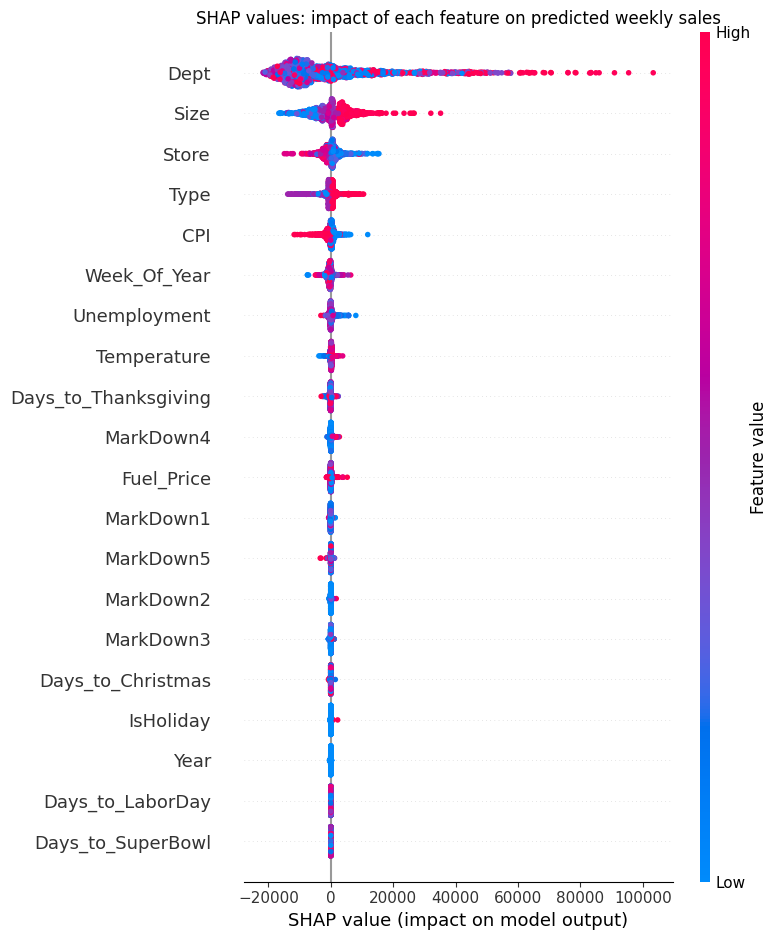

In [46]:
import shap
import matplotlib.pyplot as plt

X_val_sample = X_val.sample(2000, random_state=42)
X_val_sample_transformed = pd.DataFrame(
    XGB_pipeline.named_steps["Preprocessing"].transform(X_val_sample),
    columns=feature_names,
)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_val_sample_transformed)

shap.summary_plot(shap_values, X_val_sample_transformed, show=False)
plt.title("SHAP values: impact of each feature on predicted weekly sales")
plt.tight_layout()
plt.show()

**Reading the plots:**

* **Dept, Size, Store and Type dominate.** *What* is sold and *where* explains most of the sales level: larger stores (red on `Size`) and Type A stores push predictions up, and a handful of departments produce the very large positive SHAP values (up to +$100k).
* **CPI** has a clear negative effect (high CPI → lower predictions). CPI is regional and almost constant per store, so the model most likely uses it as a *store location proxy*, not as an economic driver. It should not be read as causal.
* **Seasonality** is carried by `Week_Of_Year` and `Days_to_Thanksgiving`. `Days_to_SuperBowl` and `Days_to_LaborDay` have **zero importance**: they could be dropped without loss.
* Markdowns, Temperature and Fuel_Price have a small impact, consistent with the correlation matrix from the EDA.

**Important caveat on the validation set:** the 2012 data stops on **2012-10-26**, so the validation set contains **no Thanksgiving and no Christmas weeks**, the biggest peaks of the year. That explains why the holiday-week error (2,857) is close to the non-holiday error (2,726): the hardest weeks were never tested. The WMAE above is therefore optimistic compared to what Kaggle would measure on the test set (Nov 2012 → Jul 2013, which includes Thanksgiving and Christmas 2012).

## What sections 8 and 9 taught us

Three lessons from the baseline models lead directly to the final model:

1. **The validation set is too easy.** The 2012 data stops on 2012-10-26, so the validation never tested Thanksgiving or Christmas, the weeks that matter most for the WMAE. A better validation must contain them.
2. **`Store` and `Dept` are used as plain numbers.** They are the most important features, but department 92 is not "bigger" than department 91. The model would learn faster from the **usual sales level** of each store/department pair.
3. **The seasonal pattern repeats every year** (section 4.2), yet no feature tells the model what happened **the same week last year**.

These ideas were tested in `Notebook_Experiments.ipynb` (holiday-aware validation, lag features, out-of-fold encoding, ideas from the competition winner). The next section only keeps what worked.

## 10. Final model: LightGBM + seasonal naive ensemble

**What the experiments showed:**

1. On a **validation split that contains Thanksgiving and Christmas** (train until 2011-10-28, validate on the next 52 weeks), every model scores worse than on the 2012 split: the old scores were optimistic.
2. **Lag features** (sales of the same week 52 weeks earlier) and the **store/department sales level** improve LightGBM's WMAE by 41%. Only lags of 52 weeks or more are used, because the test set goes up to 39 weeks ahead: shorter lags would not be known when predicting.
3. A **seasonal naive forecast** ("same week last year", on a history denoised across stores with an SVD, the key idea of the competition winner) is surprisingly strong on its own, and it makes **different errors** from LightGBM. Their 50/50 average beats both.
4. Once the method is validated, the model is **retrained on all the data** before predicting the test set.

The final model is therefore **50% LightGBM + lags, 50% SVD seasonal naive**. The weight is fixed in advance (not tuned on the validation set), and the SVD keeps 10 components out of the 45 stores.

All the feature engineering and the ensemble logic live in `walmart_features.py`, shared with `app.py`, so the app computes exactly the same predictions as this notebook.

In [47]:
import joblib
import os
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score
from walmart_features import (load_raw, build_base_features, add_lag_features, make_lgbm_pipeline,
                              svd_denoise, predict_ensemble, wmae, FEATURES, HOLIDAYS, SVD_RANK, LGBM_WEIGHT)

train_raw, test_raw, feature_store = load_raw()
full = build_base_features(train_raw, feature_store)
test_full = build_base_features(test_raw, feature_store)

### 10.1 Evaluation on the holiday-aware split

**Why a new evaluation?** The final model must be judged on a validation year that contains the holiday peaks. The lag features, the store/department statistics and the SVD are all computed **from the training period only**, so no validation sales leak into the predictions.

In [48]:
CUTOFF = pd.Timestamp("2011-10-28")
tr = full[full["Date"] <= CUTOFF]
va = full[full["Date"] > CUTOFF].reset_index(drop=True)

tr_lag = add_lag_features(tr, history=tr)
holdout_model = make_lgbm_pipeline().fit(tr_lag[FEATURES], tr_lag["Weekly_Sales"])
ensemble_pred, lgbm_pred, naive_pred = predict_ensemble(holdout_model, va, history=tr,
                                                        denoised_history=svd_denoise(tr))

peaks = va["Date"].isin([pd.Timestamp(d) for h in ("Thanksgiving", "Christmas") for d in HOLIDAYS[h].values()]).values
y = va["Weekly_Sales"].values
evaluation = pd.DataFrame([
    {"Model": name,
     "WMAE": wmae(y, pred, va["IsHoliday"] == 1),
     "MAE": mean_absolute_error(y, pred),
     "R²": r2_score(y, pred),
     "MAE Thanks/Xmas": mean_absolute_error(y[peaks], pred[peaks])}
    for name, pred in [("LightGBM + lags", lgbm_pred),
                       (f"Seasonal naive (SVD rank {SVD_RANK})", naive_pred),
                       (f"Ensemble ({LGBM_WEIGHT:.0%} / {1 - LGBM_WEIGHT:.0%})", ensemble_pred)]
])
print(f"Validation: {va['Date'].min().date()} -> {va['Date'].max().date()} ({len(va):,} rows)")
evaluation.round({"WMAE": 0, "MAE": 0, "R²": 4, "MAE Thanks/Xmas": 0})

Validation: 2011-11-04 -> 2012-10-26 (154,386 rows)


,Model,WMAE,MAE,R²,MAE Thanks/Xmas
0,LightGBM + lags,2068.0,1960.0,0.9637,2988.0
1,Seasonal naive (SVD rank 10),1887.0,1813.0,0.9703,2500.0
2,Ensemble (50% / 50%),1818.0,1764.0,0.9722,2285.0


In [49]:
# saved for the app's "Model Performance" tab: the deployed model is retrained on all data,
# so its own predictions on this period would not be an honest evaluation
va.assign(Predicted=ensemble_pred, LightGBM=lgbm_pred, Seasonal_Naive=naive_pred)[
    ["Date", "Store", "Dept", "IsHoliday", "Weekly_Sales", "Predicted", "LightGBM", "Seasonal_Naive"]
].to_csv("model_validation.csv.gz", index=False, float_format="%.2f")
print(f"model_validation.csv.gz: {os.path.getsize('model_validation.csv.gz') / 1e6:.1f} MB")

model_validation.csv.gz: 2.9 MB


In [50]:
weekly = (va.assign(Ensemble=ensemble_pred, LightGBM=lgbm_pred, Naive=naive_pred)
          .groupby("Date", as_index=False)[["Weekly_Sales", "Ensemble", "LightGBM", "Naive"]].sum())

fig = go.Figure()
fig.add_trace(go.Scatter(x=weekly["Date"], y=weekly["Weekly_Sales"], name="Actual", line=dict(width=3, color="black")))
fig.add_trace(go.Scatter(x=weekly["Date"], y=weekly["Ensemble"], name="Ensemble", line=dict(width=3)))
fig.add_trace(go.Scatter(x=weekly["Date"], y=weekly["LightGBM"], name="LightGBM alone", line=dict(width=1, dash="dot")))
fig.add_trace(go.Scatter(x=weekly["Date"], y=weekly["Naive"], name="Seasonal naive alone", line=dict(width=1, dash="dot")))
fig.update_layout(title="Total weekly sales, Nov 2011 → Oct 2012: actual vs predicted", title_x=0.5,
                  xaxis_title="Week", yaxis_title="Total Weekly Sales ($)",
                  template="plotly_white", hovermode="x unified", width=1100, height=500)
fig.show()

The plot shows why the ensemble works: LightGBM tends to over-estimate the weeks before Christmas, while the seasonal naive forecast follows last year's pattern closely. Their average is closer to reality than either of them.

In [51]:
holdout_lgbm = holdout_model.named_steps["Model"]
importance = (pd.DataFrame({"Feature": holdout_lgbm.feature_name_,
                            "Gain": holdout_lgbm.booster_.feature_importance(importance_type="gain")})
              .assign(Share=lambda d: d["Gain"] / d["Gain"].sum())
              .sort_values("Share"))

fig = px.bar(importance, x="Share", y="Feature", orientation="h",
             title="LightGBM component: share of total gain per feature")
fig.update_layout(template="plotly_white", title_x=0.5, width=900, height=650, xaxis_tickformat=".0%")
fig.show()

In the LightGBM part, the **store/department sales level** (`Store_Dept_Mean`, `Store_Dept_Median`) now carries most of the information that `Store`, `Dept`, `Size` and `Type` had to share in the baseline model.

### 10.2 Retraining on all data and saving

**Why retrain?** The evaluation above deliberately hid the most recent year from the model. Now that the method is validated, the LightGBM part is retrained on **everything we know** (2010-02-05 → 2012-10-26), because the most recent weeks are the closest to the period we have to predict. The seasonal naive part uses the full denoised history. Only the LightGBM pipeline needs to be saved: the SVD is recomputed from `train.csv` in about a second.

In [52]:
full_lag = add_lag_features(full, history=full)
final_model = make_lgbm_pipeline().fit(full_lag[FEATURES], full_lag["Weekly_Sales"])

joblib.dump(final_model, "walmart_lgbm_model.pkl")
print(f"walmart_lgbm_model.pkl: {os.path.getsize('walmart_lgbm_model.pkl') / 1e6:.1f} MB")

walmart_lgbm_model.pkl: 2.9 MB


### 10.3 Kaggle submission

**Why this format?** Kaggle expects one row per store, department and week of `test.csv`, with an `Id` written as `Store_Dept_Date`. The `Id` is built from the data itself and compared to `sampleSubmission.csv`, so the rows can never be misaligned.

In [53]:
test_pred, _, _ = predict_ensemble(final_model, test_full, history=full, denoised_history=svd_denoise(full))

submission = pd.DataFrame({
    "Id": test_full["Store"].astype(str) + "_" + test_full["Dept"].astype(str) + "_"
          + test_full["Date"].dt.strftime("%Y-%m-%d"),
    "Weekly_Sales": test_pred,
})

# sanity checks against Kaggle's expected format
sample = pd.read_csv("./Data/sampleSubmission.csv")
assert len(submission) == len(sample) and set(submission["Id"]) == set(sample["Id"])

submission.to_csv("walmart_submission.csv", index=False)
print("Submission saved to walmart_submission.csv")
submission.head()

Submission saved to walmart_submission.csv


,Id,Weekly_Sales
0,1_1_2012-11-02,39457.215862
1,1_1_2012-11-09,20686.491562
2,1_1_2012-11-16,19550.243815
3,1_1_2012-11-23,20663.186290
4,1_1_2012-11-30,24399.840815


## Conclusion

| Step | Model | Validation | WMAE |
|-|-|-|-|
| Baseline | XGBoost (tuned) | 2012 (no Thanksgiving / Christmas) | 2,752 |
| Final | 50% LightGBM + lags, 50% SVD seasonal naive | Nov 2011 → Oct 2012 (with Thanksgiving / Christmas) | **1,818** |

The two WMAE are measured on different validation periods, and the second one is the harder test, which makes the improvement even more meaningful.

The biggest gains did not come from more complex algorithms but from **understanding the problem**: a validation set that contains the important weeks, features that describe each store/department and last year's sales, and a simple seasonal forecast that complements the tree model.